# Skin Lesion Classification Using CNN


An end-to-end neural network pipeline using the HAM10000 dataset.

**Author:** Mina Tayebi

**Date:** June 2026

## 1. Problem Definition

### 1.1 Problem Context
Accurate classification of skin lesions from dermatoscopic images can support the analysis of different lesion types. However, distinguishing visually similar lesions can be challenging and requires specialized expertise.
In this project, the goal is to develop and evaluate deep learning models that classify dermatoscopic images from the HAM10000 dataset into seven skin lesion categories. A custom CNN trained from scratch is compared with transfer learning using MobileNetV2 and EfficientNetB0 to evaluate how effectively these approaches can distinguish between the lesion classes.
Because the dataset is highly imbalanced, model performance is evaluated using macro-F1 and macro-recall in addition to accuracy.

### 1.2 Machine Learning Formulation

This is a supervised multi-class image classification problem.
- **Input:** A dermatoscopic image of a skin lesion.
- **Output:** one of the seven diagnostic classes.

The project compares a custom convolutional neural network (CNN) trained from scratch with transfer learning using MobileNetV2 and EfficientNetB0. Because the dataset is highly imbalanced, accuracy alone may not reflect performance across all lesion classes. Therefore, macro-F1 and macro-recall are used alongside accuracy to provide a more balanced evaluation.

## 2. Setup

In [1]:
import tensorflow as tf
import keras


In [2]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from pathlib import Path

import tensorflow as tf
import keras
from keras import layers, optimizers, callbacks
from keras.applications import EfficientNetB0, ResNet50

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix, f1_score,
    recall_score, accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import ConfusionMatrixDisplay

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

## 3. Dataset and Exploratory Data Analysis

### 3.1 Dataset Setup

In [4]:
DATA_DIR = Path('data')
MODEL_DIR = Path('models')

DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

In [5]:
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p data

Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [04:45<00:00, 19.6MB/s]



In [6]:
zip_path = DATA_DIR/'skin-cancer-mnist-ham10000.zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(DATA_DIR)

In [7]:
list(DATA_DIR.iterdir())

[PosixPath('data/HAM10000_images_part_2'),
 PosixPath('data/skin-cancer-mnist-ham10000.zip'),
 PosixPath('data/HAM10000_metadata.csv'),
 PosixPath('data/hmnist_8_8_RGB.csv'),
 PosixPath('data/hmnist_8_8_L.csv'),
 PosixPath('data/HAM10000_images_part_1'),
 PosixPath('data/hmnist_28_28_RGB.csv'),
 PosixPath('data/hmnist_28_28_L.csv'),
 PosixPath('data/ham10000_images_part_1'),
 PosixPath('data/ham10000_images_part_2')]

### 3.2 Dataset Overview

The HAM10000 dataset is a public benchmark dataset containing 10,015 dermatoscopic images of pigmented skin lesions, collected from different clinical sources. The images are labeled into seven diagnostic categories. Diagnoses were established through histopathology, expert consensus, follow-up examinations, or confocal microscopy (Tschandl, Rosendahl & Kittler, 2018).

In [8]:
df = pd.read_csv(DATA_DIR / 'HAM10000_metadata.csv')
print(df.shape)
df.head()

(10015, 7)


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [9]:
df.info()
print("\nMissing values per column:")
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   lesion_id     10015 non-null  object 
 1   image_id      10015 non-null  object 
 2   dx            10015 non-null  object 
 3   dx_type       10015 non-null  object 
 4   age           9958 non-null   float64
 5   sex           10015 non-null  object 
 6   localization  10015 non-null  object 
dtypes: float64(1), object(6)
memory usage: 547.8+ KB

Missing values per column:
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dtype: int64


### 3.3 Exploratory Data Analysis

The metadata contains one row per image, including the diagnosis label and patient-related attributes. The exploratory analysis focuses on:

- class distribution and imbalance
- Multiple images belonging to the same lesion
- Missing values
- Patient characteristics, including age, sex, and lesion location.

### 3.3.1 Class distribution

In [10]:
LABEL_MAP = {
    'nv': 'Melanocytic nevi',
    'mel': 'Melanoma',
    'bkl': 'Benign keratosis-like lesions',
    'bcc': 'Basal cell carcinoma',
    'akiec': 'Actinic keratoses',
    'vasc': 'Vascular lesions',
    'df': 'Dermatofibroma'
}
MALIGNANT_OR_PREMALIGNANT = {'mel', 'bcc', 'akiec'}

class_counts = df['dx'].value_counts()
class_percnt = (class_counts / class_counts.sum()*100).round(2)

summary = pd.DataFrame({
    'label': class_counts.index.map(LABEL_MAP),
    'count': class_counts.values,
    'percentage': class_percnt.values,
    'clinical_risk': ['malignant/pre-malignant'
     if c in MALIGNANT_OR_PREMALIGNANT
    else 'benign'
    for  c in class_counts.index]
})
summary

,label,count,percentage,clinical_risk
0,Melanocytic nevi,6705,66.95,benign
1,Melanoma,1113,11.11,malignant/pre-malignant
2,Benign keratosis-like lesions,1099,10.97,benign
3,Basal cell carcinoma,514,5.13,malignant/pre-malignant
4,Actinic keratoses,327,3.27,malignant/pre-malignant
5,Vascular lesions,142,1.42,benign
6,Dermatofibroma,115,1.15,benign


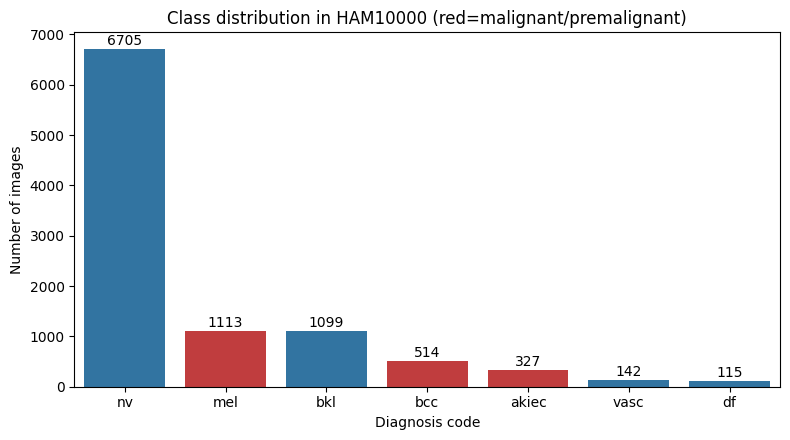

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))

palette = [
    '#d62728' if c in MALIGNANT_OR_PREMALIGNANT else '#1f77b4'
    for c in class_counts.index
]

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette=palette,
    legend=False,
    ax=ax
)

ax.set_title('Class distribution in HAM10000 (red=malignant/premalignant)')
ax.set_xlabel('Diagnosis code')
ax.set_ylabel('Number of images')

for i, v in enumerate(class_counts.values):
    ax.text(i, v + 80, str(v), ha='center')

plt.tight_layout()
plt.show()

**Observation:**

The dataset is highly imbalanced. The 'nv' class represents approximately two-thirds of all images, while classes such as 'df' and 'vasc' far fewer samples. This imbalance  means that overall accuracy may be dominated by the majority class and may not adequately reflect performance across all lesion categories.

Therefore, macro-F1 and macro-recall are considered alongsige accuracy model evaluation. Data augmentation is also applied to the training data to increase image variation and support model generalization.

#### 3.3.2 Multiple Images per Lesion

In [12]:
dup_lesions = df['lesion_id'].value_counts()

print(f'Unique lesions: {df['lesion_id'].nunique()}')
print(f'Total images: {len(df)}')
print(f'Lesions with >1 image: {(dup_lesions >1).sum()}'
      f'({(dup_lesions >1).sum()/len(dup_lesions)*100:.1f}% of lesions)')


Unique lesions: 7470
Total images: 10015
Lesions with >1 image: 1956(26.2% of lesions)


**Observation:**
Approximately 26% of lesions have multiple images, which may represent different angels or levels of magnification. Therefore, an image-level-split could place images of the same lesion in different data partitions, creating a risk of data leakage.

To reduces the risk of data leakage between training, validation and test sets, the dataset is split by 'lesion_id', ensuring that all images from the same lesion remain within the same training, valdation, or test partition.

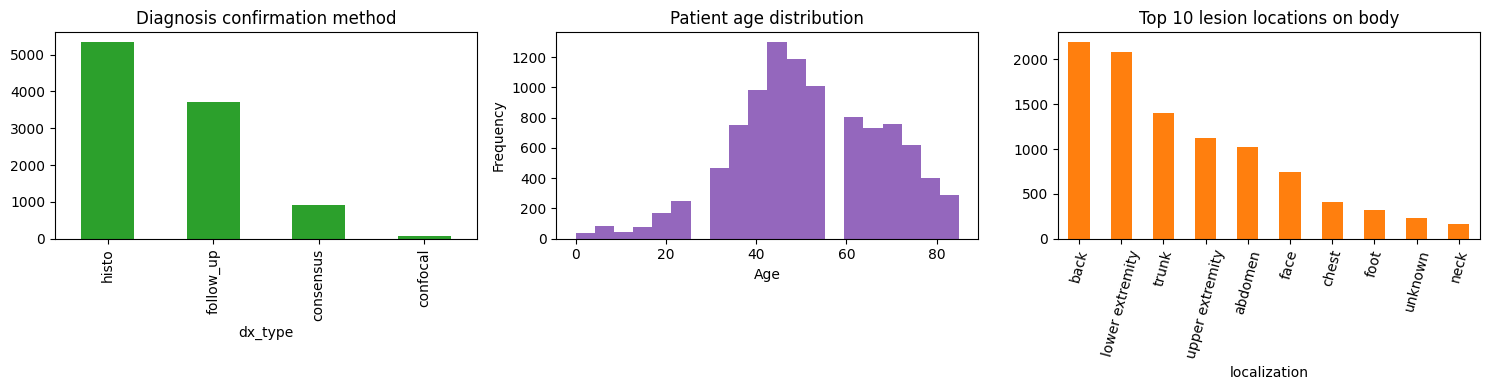


Sex distribution:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64


In [13]:
fig, axes = plt.subplots(1,3, figsize=(15,4))

df['dx_type'].value_counts().plot(kind='bar', ax=axes[0],
                                  color='#2ca02c')
axes[0].set_title('Diagnosis confirmation method')
axes[0].set_xlabel('dx_type')

df['age'].plot(kind='hist', bins=20, ax=axes[1], color='#9467bd')
axes[1].set_title('Patient age distribution')
axes[1].set_xlabel('Age')

df['localization'].value_counts().head(10).plot(kind='bar', ax=axes[2],
                                                color='#ff7f0e')
axes[2].set_title('Top 10 lesion locations on body')
axes[2].tick_params(axis='x', rotation=75)

plt.tight_layout()
plt.show()

print('\nSex distribution:')
print(df['sex'].value_counts(dropna=False))


**Observation:**
The dataset contains slightly more male than female patients, with only a small number of records having unknown sex or missing values. Approximately half of the diagnoses are confirmed by histopathology, while the remaining cases are based on othe diagnistic methods such as follow-up, expert consensus, and confocal microscopy.

## 4. Data Preprocessing

### 4.1 Building Image File Paths

In [14]:
image_paths ={}
for folder in ['HAM10000_images_part_1', 'HAM10000_images_part_2']:
  folder_path = DATA_DIR / folder

  if folder_path.exists():
    for image_path in folder_path.glob('*.jpg'):
      image_paths[image_path.stem]=str(image_path)

df['filepath'] = df['image_id'].map(image_paths)
print(
    'Images successfully matched to df:',
    df['filepath'].notna().sum(),
    '/',
    len(df)
)
df = df.dropna(subset=['filepath']).reset_index(drop=True)
df.head()

Images successfully matched to df: 10015 / 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,filepath
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,data/HAM10000_images_part_1/ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,data/HAM10000_images_part_1/ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,data/HAM10000_images_part_1/ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,data/HAM10000_images_part_1/ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,data/HAM10000_images_part_2/ISIC_0031633.jpg


Every image_id is mapped to its corresponding image file path.

### 4.2 Label Encoding

In [15]:
CLASSES = sorted(df['dx'].unique())
CLASS_To_INDEX = {c: i for i,c in enumerate(CLASSES)}
INDEX_To_CLASS ={i:c for c, i in CLASS_To_INDEX.items()}
NUM_CLASSES = len(CLASSES)

df['label_idx'] = df['dx'].map(CLASS_To_INDEX)
print("Classes:", CLASSES)
print('Number of Classes:', NUM_CLASSES)

Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Number of Classes: 7


Each diagnistic class was mapped to an integer index for model training.

### 4.3 Train-Validation-Test Split

In [16]:
unique_lesions = df['lesion_id'].unique()

lesions_train, lesions_temp = train_test_split(unique_lesions, test_size=0.30, random_state=SEED)
lesion_val, lesion_test = train_test_split(lesions_temp, test_size=0.50, random_state=SEED)

df_train = df[df['lesion_id'].isin(lesions_train)].reset_index(drop=True)
df_val = df[df['lesion_id'].isin(lesion_val)].reset_index(drop=True)
df_test = df[df['lesion_id'].isin(lesion_test)].reset_index(drop=True)

print(f'Train images: {len(df_train)}')
print(f'Validation images: {len(df_val)}')
print(f'Test images: {len(df_test)}')


Train images: 6987
Validation images: 1512
Test images: 1516


To prevent data leakage, the dataset was split by 'lesion-id' rather than individual images. This ensures that all images belonging to the same lesion remain in the same data partition.
The data was divided into approximately 70% training, 15% validation, and 15% test sets. A fixed random seed was used to make the split reproducible.

### 4.4 Computing class weights

In [17]:
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(NUM_CLASSES),
    y=df_train['label_idx'].values
)

CLASS_WEIGHTS = dict(enumerate(class_weights_array))
print('Class weights:')
for idx, w in CLASS_WEIGHTS.items():
  print(f'{INDEX_To_CLASS[idx]}: {w:.2f}')

Class weights:
akiec: 4.25
bcc: 2.81
bkl: 1.36
df: 13.31
mel: 1.29
nv: 0.21
vasc: 11.74


Class weights were computed a possible strategy for addressing class imbalance. As expected, rare classes such as 'df' and 'vasc' received substantially higher weights, while the majority 'nv' class received the lowest weight.

Class weighting was tested during model development but resulted in lower validation performance. Therefore, it was not used in the final model.

### 4.5 Image Data Pipeline

The image data pipeline was prepared as follows:

- Images were resized to 128*128 pixels for the custom CNN.
- Data augmentation, including random flipping, rotation, zoom, contrast adjustment, was applied only to the training set to increase image variation and support generalization.
- Pixel values were normalized to the [0,1] range for the custom CNN.
- For transfer learning with MobileNetV2 and EfficientNetB0, images were resized to 224*224 pixels to match a standard input size for the pretrained models.

In [18]:
IMG_SIZE =128
BATCH_SIZE = 32

def load_and_preprocess(
    filepath,
    label,
    img_size=IMG_SIZE,
    normalize=True
):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [img_size, img_size])
    img = tf.cast(img, tf.float32)

    if normalize:
        img = img / 255.0

    return img, label

def make_dataset(
    df,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    augment=False,
    shuffle=False,
    normalize=True
):
    paths = df["filepath"].values
    labels = df["label_idx"].values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    ds = ds.map(
        lambda p, l: load_and_preprocess(
            p,
            l,
            img_size=img_size,
            normalize=normalize
        ),
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if augment:
        augmenter = keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.15),
            layers.RandomZoom(0.15),
            layers.RandomContrast(0.15),
        ])

        ds = ds.map(
            lambda x, y: (augmenter(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(df),
            seed=SEED
        )

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)

    return ds

ds_train = make_dataset(df_train, augment=True, shuffle=True)
ds_val = make_dataset(df_val, augment=False, shuffle=False)
ds_test = make_dataset(df_test, augment=False, shuffle=False)

print('tf.data pipelines built!')

tf.data pipelines built!


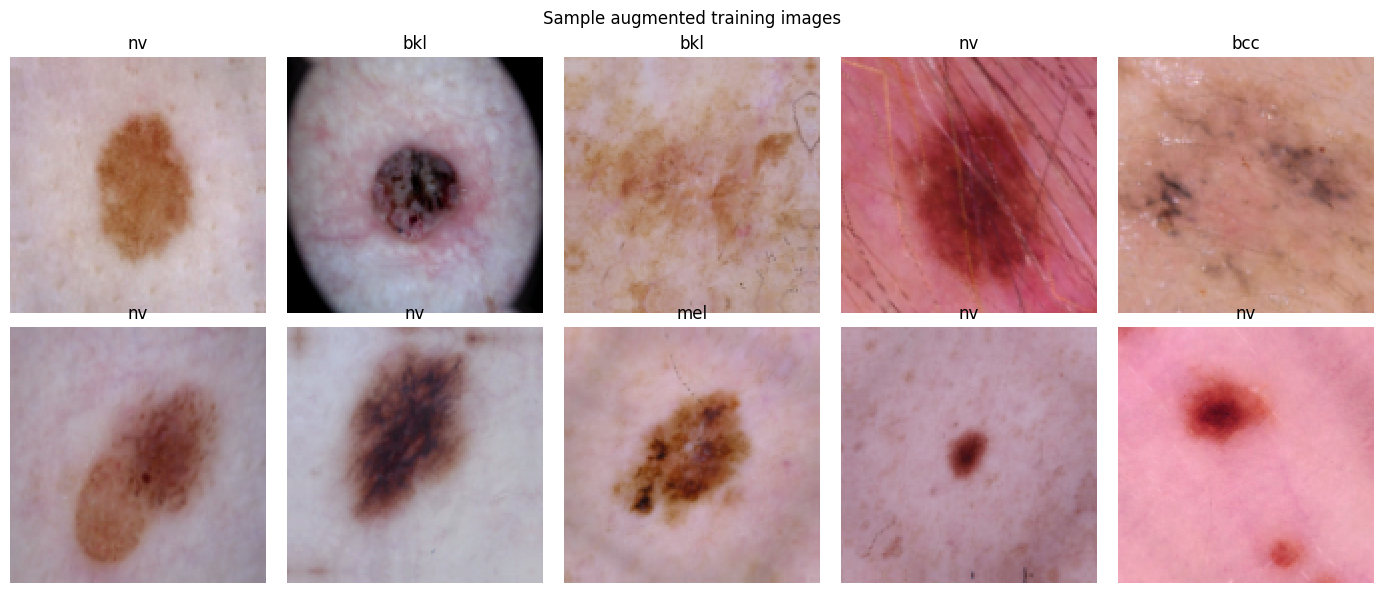

In [19]:
sample_batch_imgs, sample_batch_labels= next(iter(ds_train))

fig, axes = plt.subplots(2,5, figsize=(14,6))
for i, ax in enumerate(axes.flat):
  ax.imshow(sample_batch_imgs[i].numpy())
  ax.set_title(INDEX_To_CLASS[int(sample_batch_labels[i])])
  ax.axis('off')
plt.suptitle('Sample augmented training images')
plt.tight_layout()
plt.show()

## 5. Model Training

In this section, three deep learning approaches are developed and compared:
- A custom CNN trained from scratch.
- Transfer learning with MobileNetV2 using feature extraction followed by fine-tuning.
- Transfer learning with an EfficientNetB0 using feature extraction followed by fine-tuning.

Early stopping and learning-rate scheduling are used during training to control the training process and reduce unnecessary epochs.

### 5.1 Custom CNN Model

The custom CNN was built from scratch using the following design choices:

- He initialization was used in the convolutional and hidden dense layers.
- Batch normalization was applied after the convolutional layers to support stable training.
- RelU was used as the activation function in the convolutional and hidden dense layers.
- Dropout was used as a regularization technique to reduce the risk of overfitting.
- Global average pooling was used instead of flattening to reduce the number of trainable parameters.
- A softmax output layer was used for the seven-class classification task.

In [20]:
CNN_model = keras.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(
        32, (3,3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(
        64, (3,3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(
        128, (3,3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(
        256, (3,3),
        padding='same',
        activation='relu',
        kernel_initializer='he_normal'
    ),
    layers.BatchNormalization(),

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.4),

    layers.Dense(
        128,
        activation='relu',
        kernel_initializer='he_normal'
    ),

    layers.Dropout(0.3),

    layers.Dense(NUM_CLASSES, activation='softmax')
])



### 5.2 Training the Custom CNN Model

The custom CNN was trained using the Adam optimizer with an initial learning rate of 0.001 and sparse categorical cross-entropy as the loss function. Early stopping and learning-rate reduction were based on validation loss, while the best model checkpoint was saved during training.

In [21]:
CNN_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

CNN_checkpoint = callbacks.ModelCheckpoint(
    filepath =MODEL_DIR / 'cnn_bst.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1

)

CNN_model_callbacks = [

    CNN_checkpoint,

    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=8,
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
]

history_CNN = CNN_model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=40,
    callbacks=CNN_model_callbacks
)

Epoch 1/40
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.5955 - loss: 1.1728
Epoch 1: val_loss improved from None to 1.61101, saving model to models/cnn_bst.keras

Epoch 1: finished saving model to models/cnn_bst.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 41s 75ms/step - accuracy: 0.6489 - loss: 1.0150 - val_accuracy: 0.6376 - val_loss: 1.6110 - learning_rate: 0.0010
Epoch 2/40
216/219 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6903 - loss: 0.8796
Epoch 2: val_loss improved from 1.61101 to 0.90793, saving model to models/cnn_bst.keras

Epoch 2: finished saving model to models/cnn_bst.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 12ms/step - accuracy: 0.6867 - loss: 0.8634 - val_accuracy: 0.6548 - val_loss: 0.9079 - learning_rate: 0.0010
Epoch 3/40
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6957 - loss: 0.8115
Epoch 3: val_loss did not improve from 0.90793
219/219 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.6984 - loss: 0.8137 - val_accuracy: 0.6898 - val_loss: 0.9083 - 

**Observation:**

The CNN showed gradual improvement during training. The best validation loss of 0.69063 was achieved at epoch 26, with a validation accuracy of approximately 79.7%. The learning rate was progressively reduced when validation loss stopped improving, and early stopping terminated training after 34 epochs.

### 5.3 Transfer Learning

Two pretrained architectures, MobileNetV2 and EfficientNetB0, were evaluated using transfer learning. For both models, training was performed in two phases:

- **Phase A - Feature Extraction:** The pretrained base model was frozen, and only the newly added classification head was trained.

- **Phase B - Fine-Tuning:** Selected layers of the pretrained base model were unfrozen and trained with a small learning rate ('1e-6'), while the earlier layers and Batch Normalization layers remained frozen.

For transfer learning, the images were resized to 224*224 pixels. Model-specific preprocessing was applied within each pretrained architecture.

In [22]:
IMG_SIZE_TL = 224

ds_train_tl = make_dataset(
    df_train,
    img_size=IMG_SIZE_TL,
    augment=True,
    shuffle=True,
    normalize=False
)

ds_val_tl = make_dataset(
    df_val,
    img_size=IMG_SIZE_TL,
    augment=False,
    shuffle=False,
    normalize=False
)

ds_test_tl = make_dataset(
    df_test,
    img_size=IMG_SIZE_TL,
    augment=False,
    shuffle=False,
    normalize=False
)

#### 5.3.1 MobileNetV2

**Feature Extraction**

In [23]:
mobilenet_base_model = keras.applications.MobileNetV2(
    include_top=False,
    weights='imagenet',
    input_shape=(IMG_SIZE_TL,IMG_SIZE_TL,3)
)

mobilenet_base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [24]:
mobilenet_inputs = keras.Input(
    shape=(IMG_SIZE_TL,IMG_SIZE_TL,3)
)

x = keras.applications.mobilenet_v2.preprocess_input(mobilenet_inputs)

x=mobilenet_base_model(x, training=False)

x=layers.GlobalAveragePooling2D()(x)

x= layers.Dropout(0.3)(x)

mobilenet_outputs = layers.Dense(
    NUM_CLASSES,
    activation='softmax'
)(x)

mobilenet_model = keras.Model(
    inputs=mobilenet_inputs,
    outputs=mobilenet_outputs)

mobilenet_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [25]:
mobilenet_model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_feature_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / 'mobilenet_feature_best.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

mobilenet_feature_callbacks = [
    mobilenet_feature_checkpoint,

    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True),

    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-6)
]

history_mobilenet_feature = mobilenet_model.fit(
    ds_train_tl,
    validation_data=ds_val_tl,
    epochs=10,
    callbacks=mobilenet_feature_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.6377 - loss: 1.1615
Epoch 1: val_loss improved from None to 0.94336, saving model to models/mobilenet_feature_best.keras

Epoch 1: finished saving model to models/mobilenet_feature_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 62s 125ms/step - accuracy: 0.6818 - loss: 0.9771 - val_accuracy: 0.6978 - val_loss: 0.9434 - learning_rate: 0.0010
Epoch 2/10
216/219 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7243 - loss: 0.7931
Epoch 2: val_loss improved from 0.94336 to 0.80873, saving model to models/mobilenet_feature_best.keras

Epoch 2: finished saving model to models/mobilenet_feature_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.7262 - loss: 0.7792 - val_accuracy: 0.7169 - val_loss: 0.8087 - learning_rate: 0.0010
Epoch 3/10
215/219 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7378 - loss: 0.7446
Epoch 3: val_loss did not improve from 0.80873
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.7

In [26]:
mobilenet_feature_model = keras.models.load_model(
    MODEL_DIR / "mobilenet_feature_best.keras"
)

**Observation:**

During feature extraction, MobileNetV2 achieved its best validation loss of 0.7596 at epoch 5, with a validation accuracy of approximately 75.5%. The learning rate was reduced during training when validation loss stopped improving temporarily.

**Fine-Tuning**

In [27]:
mobilenet_base_model.trainable = True
mobilenet_fine_tune_at =120

for layer in mobilenet_base_model.layers[:mobilenet_fine_tune_at]:
  layer.trainable = False

for layer in mobilenet_base_model.layers:
  if isinstance(layer, keras.layers.BatchNormalization):
    layer.trainable = False

mobilenet_model.compile(
    optimizer = optimizers.Adam(learning_rate=1e-6),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

mobilenet_fine_tune_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / 'mobilenet_fine_tuned_best.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

mobilenet_fine_tune_callbacks = [
    mobilenet_fine_tune_checkpoint,

    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    ),

    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=1e-7
    ),
]

history_mobilenet_fine_tune = mobilenet_model.fit(
    ds_train_tl,
    validation_data=ds_val_tl,
    epochs=10,
    callbacks=mobilenet_fine_tune_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7625 - loss: 0.6366
Epoch 1: val_loss improved from None to 0.75648, saving model to models/mobilenet_fine_tuned_best.keras

Epoch 1: finished saving model to models/mobilenet_fine_tuned_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 47s 81ms/step - accuracy: 0.7670 - loss: 0.6297 - val_accuracy: 0.7361 - val_loss: 0.7565 - learning_rate: 1.0000e-06
Epoch 2/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7644 - loss: 0.6303
Epoch 2: val_loss improved from 0.75648 to 0.75275, saving model to models/mobilenet_fine_tuned_best.keras

Epoch 2: finished saving model to models/mobilenet_fine_tuned_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 21ms/step - accuracy: 0.7677 - loss: 0.6270 - val_accuracy: 0.7421 - val_loss: 0.7528 - learning_rate: 1.0000e-06
Epoch 3/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7696 - loss: 0.6325
Epoch 3: val_loss did not improve from 0.75275
219/219 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/s

In [28]:
mobilenet_fine_tuned_model = keras.models.load_model(MODEL_DIR / 'mobilenet_fine_tuned_best.keras')

**Observation**

Fine-Tuning produced a small improvement over feature extraction. The best validation loss decreased to 0.74382, while validation accuracy increased  approximately to 74.47%.

#### 5.3.2 EfficientNetB0

**Feature Extraction**

In [29]:
efficientnet_base = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3)
)

efficientnet_base.trainable = False

efficientnet_inputs = keras.Input(
    shape=(IMG_SIZE_TL, IMG_SIZE_TL, 3)
)

x = efficientnet_base(efficientnet_inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

efficientnet_outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

efficientnet_model = keras.Model(
    inputs=efficientnet_inputs,
    outputs=efficientnet_outputs
)

efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [30]:
efficientnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_feature_checkpoint = callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / "efficientnet_feature_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

efficientnet_feature_callbacks = [
    efficientnet_feature_checkpoint,

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

history_efficientnet_feature = efficientnet_model.fit(
    ds_train_tl,
    validation_data=ds_val_tl,
    epochs=10,
    callbacks=efficientnet_feature_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.6317 - loss: 1.1013
Epoch 1: val_loss improved from None to 0.89848, saving model to models/efficientnet_feature_best.keras

Epoch 1: finished saving model to models/efficientnet_feature_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 89s 187ms/step - accuracy: 0.6748 - loss: 0.9503 - val_accuracy: 0.6561 - val_loss: 0.8985 - learning_rate: 0.0010
Epoch 2/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7016 - loss: 0.8036
Epoch 2: val_loss improved from 0.89848 to 0.83509, saving model to models/efficientnet_feature_best.keras

Epoch 2: finished saving model to models/efficientnet_feature_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 21s 22ms/step - accuracy: 0.7087 - loss: 0.7867 - val_accuracy: 0.6726 - val_loss: 0.8351 - learning_rate: 0.0010
Epoch 3/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7369 - loss: 0.7300
Epoch 3: val_loss improved from 0.83509 to 0.80224, saving model to models/efficientnet_featu

In [31]:
efficientnet_feature_model = keras.models.load_model(
    MODEL_DIR / "efficientnet_feature_best.keras"
)

**Observation:**

During feature extraction, EfficientNetB0 achieved its best validation loss of 0.7293 at epoch 10, with a validation accuracy of approximately 71.8%.

**Fine-Tuning**

In [32]:
efficientnet_base.trainable = True

efficientnet_fine_tune_at = 120

for layer in efficientnet_base.layers[:efficientnet_fine_tune_at]:
    layer.trainable = False

for layer in efficientnet_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

In [33]:
efficientnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-6),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

efficientnet_fine_tune_checkpoint = callbacks.ModelCheckpoint(
    filepath=MODEL_DIR / "efficientnet_fine_tuned_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

efficientnet_fine_tune_callbacks = [
    efficientnet_fine_tune_checkpoint,

    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7
    )
]

history_efficientnet_fine_tune = efficientnet_model.fit(
    ds_train_tl,
    validation_data=ds_val_tl,
    epochs=10,
    callbacks=efficientnet_fine_tune_callbacks
)

Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7589 - loss: 0.6415
Epoch 1: val_loss improved from None to 0.72354, saving model to models/efficientnet_fine_tuned_best.keras

Epoch 1: finished saving model to models/efficientnet_fine_tuned_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 96s 186ms/step - accuracy: 0.7636 - loss: 0.6397 - val_accuracy: 0.7189 - val_loss: 0.7235 - learning_rate: 1.0000e-06
Epoch 2/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7575 - loss: 0.6474
Epoch 2: val_loss improved from 0.72354 to 0.71525, saving model to models/efficientnet_fine_tuned_best.keras

Epoch 2: finished saving model to models/efficientnet_fine_tuned_best.keras
219/219 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - accuracy: 0.7583 - loss: 0.6394 - val_accuracy: 0.7255 - val_loss: 0.7152 - learning_rate: 1.0000e-06
Epoch 3/10
217/219 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.7714 - loss: 0.6219
Epoch 3: val_loss improved from 0.71525 to 0.71217, saving model to mode

In [34]:
efficientnet_fine_tuned_model = keras.models.load_model(
    MODEL_DIR / "efficientnet_fine_tuned_best.keras"
)

**Observation:**

Fine-tuning improved EfficientNetB0 compared with feature extraction. The best validation loss decreased from 0.68601 to 0.6820, while validation accuracy decreases from approximately 79.00% to 74.5%

### 5.4 Performance Comparison on the Validation Set

The Custom CNN, MobileNetV2, and EfficientNetB0 models are compared on the validation set using accuracy, macro-F1, and macro-recall. Both feature extraction and fine-tuned versions of the pretrained models are included in the comparison.

In [35]:
def evaluate_model(model, dataset):
    y_true = []
    y_pred = []

    for images, labels in dataset:
        predictions = model.predict(images, verbose=0)
        y_true.extend(labels.numpy())
        y_pred.extend(np.argmax(predictions, axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
    macro_recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    return {
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Macro Recall": macro_recall,
        "y_true": y_true,
        "y_pred": y_pred
    }

In [36]:
cnn_results = evaluate_model(
    CNN_model,
    ds_val
)

mobilenet_feature_results = evaluate_model(
    mobilenet_feature_model,
    ds_val_tl
)

mobilenet_fine_tuned_results = evaluate_model(
    mobilenet_fine_tuned_model,
    ds_val_tl
)

efficientnet_feature_results = evaluate_model(
    efficientnet_feature_model,
    ds_val_tl
)

efficientnet_fine_tuned_results = evaluate_model(
    efficientnet_fine_tuned_model,
    ds_val_tl
)

**Model Comparison**

The comparison table is generated directly from the validation predictions of the current model runs.

In [37]:
comparison_df = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "MobileNetV2 - Feature Extraction",
        "MobileNetV2 - Fine-Tuned",
        "EfficientNetB0 - Feature Extraction",
        "EfficientNetB0 - Fine-Tuned"
    ],
    "Accuracy": [
        cnn_results["Accuracy"],
        mobilenet_feature_results["Accuracy"],
        mobilenet_fine_tuned_results["Accuracy"],
        efficientnet_feature_results["Accuracy"],
        efficientnet_fine_tuned_results["Accuracy"]
    ],
    "Macro F1": [
        cnn_results["Macro F1"],
        mobilenet_feature_results["Macro F1"],
        mobilenet_fine_tuned_results["Macro F1"],
        efficientnet_feature_results["Macro F1"],
        efficientnet_fine_tuned_results["Macro F1"]
    ],
    "Macro Recall": [
        cnn_results["Macro Recall"],
        mobilenet_feature_results["Macro Recall"],
        mobilenet_fine_tuned_results["Macro Recall"],
        efficientnet_feature_results["Macro Recall"],
        efficientnet_fine_tuned_results["Macro Recall"]
    ]
})

comparison_df.round(3)

,Model,Accuracy,Macro F1,Macro Recall
0,Custom CNN,0.747,0.500,0.476
1,MobileNetV2 - Feature Extraction,0.733,0.449,0.417
2,MobileNetV2 - Fine-Tuned,0.745,0.443,0.417
3,EfficientNetB0 - Feature Extraction,0.718,0.452,0.393
4,EfficientNetB0 - Fine-Tuned,0.747,0.529,0.463


**Observation:**

EfficientNetB0 after fine-tuning achieved the highest macro-F1 (0.529) and macro-recall (0.463), while also reaching 74.7% validation accuracy. This indicates the strongest overall performance across the imbalanced lesion classes among the evaluated models.

### 5.5 Confusion Matrices

Confusion matrices are used to examine class-level prediction patterns for each model. Each matrix is generated from the validation predictions stored separately for the corresponding model.

In [38]:
def plot_confusion_matrix(results, title):
    ConfusionMatrixDisplay.from_predictions(
        results["y_true"],
        results["y_pred"],
        display_labels=CLASSES,
        xticks_rotation=45
    )

    plt.title(title)
    plt.tight_layout()
    plt.show()

**Confusion Matrix - Custom CNN**

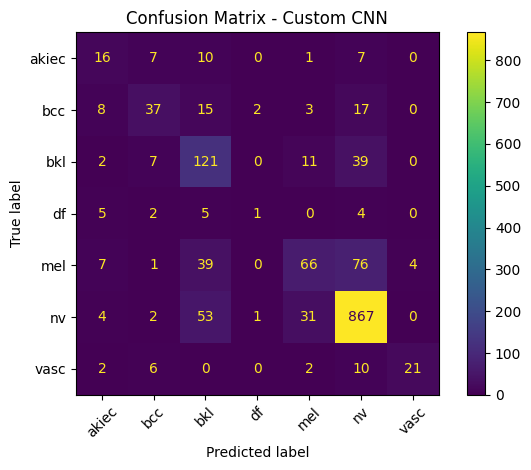

In [39]:
plot_confusion_matrix(
    cnn_results,
    "Confusion Matrix - Custom CNN"
)

**Confusion Matrix - MobileNetV2 Feature Extraction**

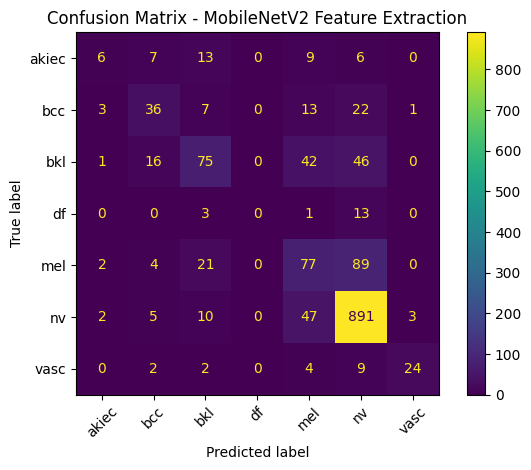

In [40]:
plot_confusion_matrix(
    mobilenet_feature_results,
    "Confusion Matrix - MobileNetV2 Feature Extraction"
)

**Confusion Matrix - MobileNetV2 Fine-Tuned**

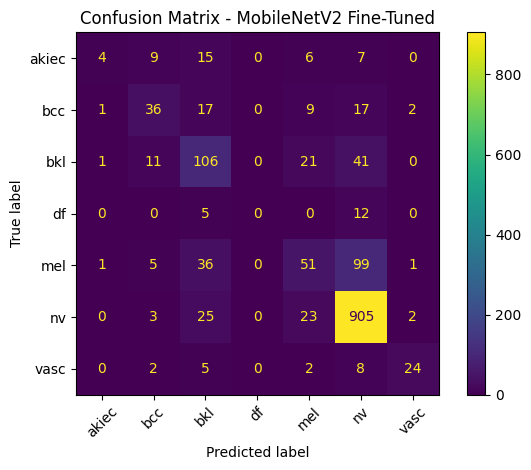

In [41]:
plot_confusion_matrix(
    mobilenet_fine_tuned_results,
    "Confusion Matrix - MobileNetV2 Fine-Tuned"
)

**Confusion Matrix - EfficientNetB0 Feature Extraction**

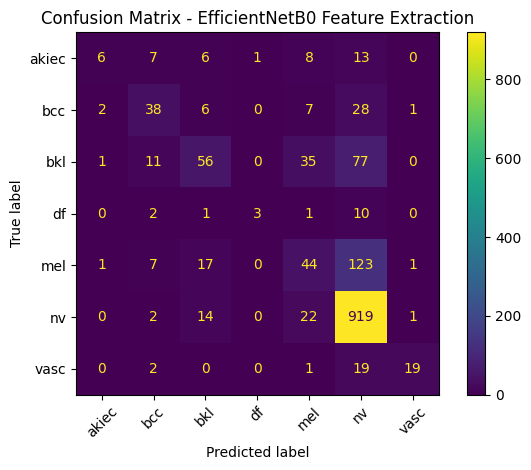

In [42]:
plot_confusion_matrix(
    efficientnet_feature_results,
    "Confusion Matrix - EfficientNetB0 Feature Extraction"
)

**Confusion Matrix - EfficientNetB0 Fine-Tuned**

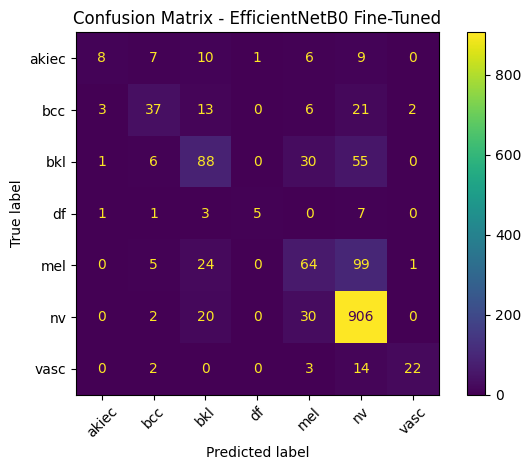

In [43]:
plot_confusion_matrix(
    efficientnet_fine_tuned_results,
    "Confusion Matrix - EfficientNetB0 Fine-Tuned"
)

**Observation**

The confusion matrices show that all models performed better on the majority class(nv) than on several minority classes. Many errors involved samples from other classes being predicted as 'nv'. The EfficientNetB0 showed better class-level performance across several minority classes, which is consistent with its higher macro-F1 and macro-recall scores.

## 6. Selecting the Best Model

The best-performing model is selected based on validation macro-F1. Macro-F1 is used as the primary selection metric because the dataset is highly imbalanced and this metric gives equal importance to all classes.

After model selection, the selected model is evaluated once on the held-out test set to estimate its final performance on unseen data.

**Model Selection**

In [44]:
models = {
    "Custom CNN": (CNN_model, ds_test),
    "MobileNetV2 - Feature Extraction": (
        mobilenet_feature_model,
        ds_test_tl
    ),
    "MobileNetV2 - Fine-Tuned": (
        mobilenet_fine_tuned_model,
        ds_test_tl
    ),
    "EfficientNetB0 - Feature Extraction": (
        efficientnet_feature_model,
        ds_test_tl
    ),
    "EfficientNetB0 - Fine-Tuned": (
        efficientnet_fine_tuned_model,
        ds_test_tl
    )
}

In [45]:
best_row = comparison_df.sort_values(
    "Macro F1",
    ascending=False
).iloc[0]

best_model, best_test_dataset = models[best_row["Model"]]

print("Selected model:", best_row["Model"])
print(f'Validation Macro F1: {best_row["Macro F1"]:.4f}')

Selected model: EfficientNetB0 - Fine-Tuned
Validation Macro F1: 0.5287


In [46]:
test_results = evaluate_model(
    best_model,
    best_test_dataset
)

print("=== FINAL TEST SET PERFORMANCE ===")
print(f'Macro F1: {test_results["Macro F1"]:.4f}')
print(f'Macro Recall: {test_results["Macro Recall"]:.4f}')
print(f'Accuracy: {test_results["Accuracy"]:.4f}')

=== FINAL TEST SET PERFORMANCE ===
Macro F1: 0.4874
Macro Recall: 0.4319
Accuracy: 0.7652


**Classification Report - Final Test Set**

In [47]:
print(
    classification_report(
        test_results["y_true"],
        test_results["y_pred"],
        target_names=CLASSES,
        zero_division=0
    )
)

              precision    recall  f1-score   support

       akiec       0.55      0.24      0.33        51
         bcc       0.67      0.48      0.56        77
         bkl       0.58      0.49      0.53       185
          df       0.40      0.09      0.14        23
         mel       0.41      0.42      0.41       145
          nv       0.85      0.93      0.89      1019
        vasc       1.00      0.38      0.55        16

    accuracy                           0.77      1516
   macro avg       0.64      0.43      0.49      1516
weighted avg       0.75      0.77      0.75      1516



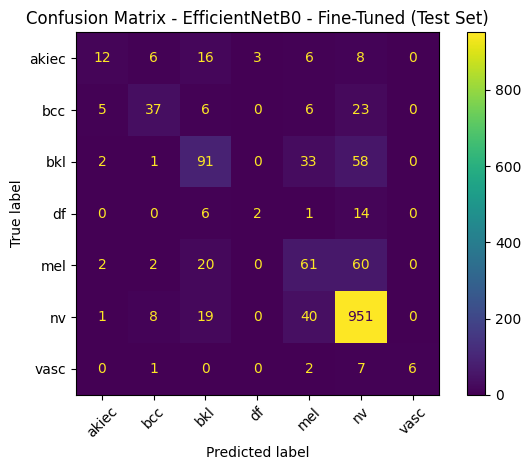

In [48]:
plot_confusion_matrix(
    test_results,
    f'Confusion Matrix - {best_row["Model"]} (Test Set)'
)

**Final Test Evaluation:**

The selected fine-tuned EfficientNetB0 achieved 76.5% accuracy, a macro-F1 of 0.4874, and macro-recall of 0.4319 on the test set. Performance varied considerably across classes. The model performed particularly well on the majority 'nv' class (F1=0.89), while performance was weaker for some minority classes, especially 'df' and 'akiec'. The confusion matrix also shows that many misclassified samples from other classes were predicted as 'nv'. This difference between overall accuracy and macro-F1 highlights the importance of evaluating class-level performance on this imbalanced dataset.

## 7. Final Discussion

### 7.1 Key Insights

- Among the evaluated models, the fine-tuned EfficientNetB0 achieved the best overall validation performance, with a macro-F1 of 0.512 and macro-recall of 0.452.
- On the test set, the selected model achieved 76.5% accuracy, a macro-F1 of 0.4874, and macro-recall of 0.4319.
- Performance varied considerably across classes. The model performed particularly well on the majority 'nv' class, while some minority classes, especially 'df' and 'akiec', were more difficult to classify.
- The difference between overall accuracy and macro-F1 shows that accuracy alone does not provide a complete picture of model performance on this imbalanced dataset.
- Fine-tuning EfficientNetB0 provided the strongest overall performance among the evaluated approaches.

### 7.2 Limitations

- The dataset is highly imbalanced, with the 'nv' class representing a large proportion of the images.
- Some minority classes contain relatively few samples, making their classification more difficult.
- The final model still showed a tendency to predict samples from several minority classes as 'nv'.
- The experiments were limited to a custom CNN and two pretrained architectures, MobileNetV2 and EfficientNetB0.

### 7.3 Recommendations for Future Work

- Explore alternative approaches for improving performance on minority classes.
- Investigate additional pretrained architectures and fine-tuning strategies.
- Perform systematic hyperparameter tuning to further optimize model performance.